In [1]:
import pandas as pd

df = pd.read_csv("data.csv")
print(df.head())
print(df.info())

  customer_id           full_name gender  age     city  favorite_category  \
0       C1001      Қасымова Айгүл   Әйел   18   Астана          Косметика   
1       C1002       Қасымов Ержан     Ер   19  Шымкент  Тұрмыстық техника   
2       C1003     Төлегенов Қанат     Ер   39    Тараз               Киім   
3       C1004  Сарсенбаев Асылбек     Ер   41   Атырау          Косметика   
4       C1005       Қалиев Жандос     Ер   34   Ақтөбе  Тұрмыстық техника   

  registration_date  total_orders  avg_order_value  days_since_last_purchase  \
0        2024-10-01             7            13600                        45   
1        2023-04-02             4            20800                       116   
2        2024-07-17             4            22500                        42   
3        2025-03-09             4            13800                        45   
4        2025-08-16             3            11600                        78   

   visits_last_month  product_views  cart_adds  discount

In [2]:
print(df.describe())
print(df.isnull().sum())
print(df["purchased"].value_counts())

              age  total_orders  avg_order_value  days_since_last_purchase  \
count  250.000000    250.000000        250.00000                250.000000   
mean    32.400000      5.520000      15599.20000                 39.940000   
std      9.513465      3.331968       7060.37072                 26.521651   
min     18.000000      1.000000       2500.00000                  1.000000   
25%     25.000000      3.000000      10725.00000                 19.000000   
50%     32.000000      5.000000      15700.00000                 34.000000   
75%     39.000000      7.000000      20675.00000                 55.000000   
max     60.000000     22.000000      33000.00000                166.000000   

       visits_last_month  product_views   cart_adds  discount_used  \
count         250.000000     250.000000  250.000000     250.000000   
mean            5.620000      21.904000    3.168000       0.412000   
std             3.370615      14.684869    3.021306       0.493182   
min             0

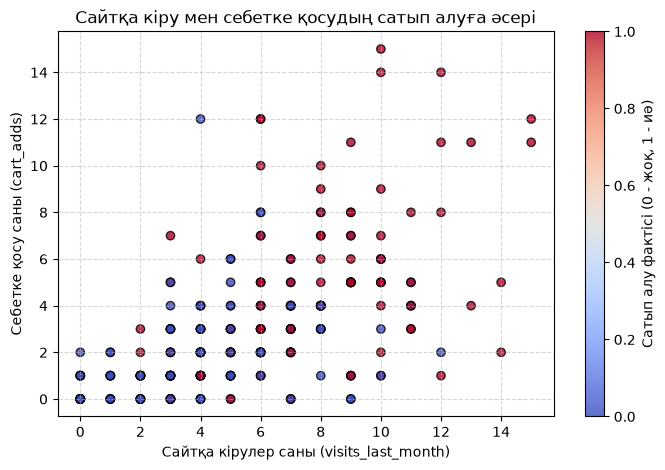

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df["visits_last_month"], df["cart_adds"], c=df["purchased"], cmap="coolwarm", alpha=0.8, edgecolors="k")
plt.xlabel("Сайтқа кірулер саны (visits_last_month)")
plt.ylabel("Себетке қосу саны (cart_adds)")
plt.title("Сайтқа кіру мен себетке қосудың сатып алуға әсері")
plt.colorbar(label="Сатып алу фактісі (0 - жоқ, 1 - иә)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

# Жынысты сандық мәнге түрлендіру (Ер -> 1, Әйел -> 0)
df["gender_code"] = df["gender"].map({"Ер": 1, "Әйел": 0})

features = ["age", "gender_code", "total_orders", "avg_order_value", "days_since_last_purchase", "visits_last_month", "cart_adds"]
X = df[features]
y = df["purchased"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [5]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[119., 81.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.59,0.41]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.04977
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['age','gender_code','total_orders',...,'days_since_last_purchase', 'visits_last_month','cart_adds']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 7)","[[31.61, 0.48, 4.82,...,37.39, 4.59, 2.18], [34.63, 0.47, 6.21,...,40.26, 7.27, 4.51]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 7)","[[ 80.64, 0.3 , 7.05,...,469.73, 8.11, 4.73], [ 98.48, 0.3 , 16.61,...,711.55, 10.62, 12.13]]"


In [6]:
y_pred = model.predict(X_test)
print(y_pred)

[0 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 0 0 1 0 1 1 0 0 0 1 0 0 0 0 1 1 1 1 0 1 0
 1 0 0 1 1 1 0 0 0 0 1 0 1]


In [7]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

Accuracy: 0.76
              precision    recall  f1-score   support

           0       0.80      0.80      0.80        30
           1       0.70      0.70      0.70        20

    accuracy                           0.76        50
   macro avg       0.75      0.75      0.75        50
weighted avg       0.76      0.76      0.76        50



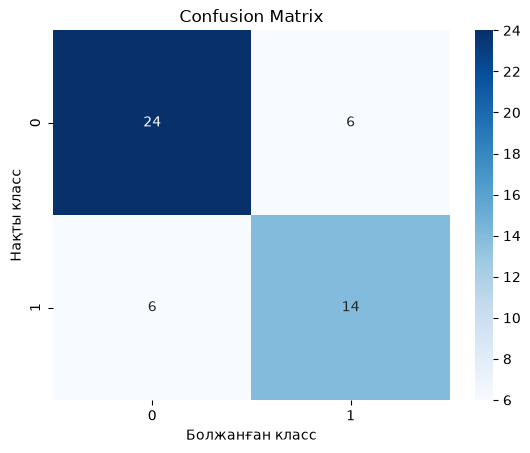

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Болжанған класс")
plt.ylabel("Нақты класс")
plt.title("Confusion Matrix")
plt.show()

In [9]:
import pandas as pd

# Жаңа клиент деректері (мысалы: жасы=34, жынысы=1 (Ер), тапсырыс саны=9, орташа чек=25000, соңғы белсенділік=15 күн бұрын, сайтқа кіру саны=12, себетке қосу=4)
new_student = pd.DataFrame([[34, 1, 9, 25000, 15, 12, 4]], columns=features)

prediction = model.predict(new_student)
print("Болжам:", prediction)

probability = model.predict_proba(new_student)
print("Класс ықтималдығы:", probability)

Болжам: [1]
Класс ықтималдығы: [[0.08208471 0.91791529]]


In [10]:
# Әртүрлі пропорциялар бойынша сынақтар (тестілеу) жүргізу
split_ratios = [0.3, 0.2, 0.1]

for test_size in split_ratios:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    # Модельді оқыту
    test_model = GaussianNB()
    test_model.fit(X_tr, y_tr)

    # Болжам жасау
    y_pred_temp = test_model.predict(X_te)

    # Дәлдікті есептеу
    acc = accuracy_score(y_te, y_pred_temp)
    print(f"Тест өлшемі {int(test_size*100)}% ({len(X_tr)} трейн / {len(X_te)} тест) -> Дәлдік (Accuracy): {acc:.4f}")

Тест өлшемі 30% (175 трейн / 75 тест) -> Дәлдік (Accuracy): 0.7200
Тест өлшемі 20% (200 трейн / 50 тест) -> Дәлдік (Accuracy): 0.7600
Тест өлшемі 10% (225 трейн / 25 тест) -> Дәлдік (Accuracy): 0.8000
